# MobileNetV2 U-Net

This notebook retrains the MobileNetV2 U-Net from our transfer learning experiments. It now uses the same data loading, split and evaluation as our U-Net and SUIM-Net notebooks, so the scores can be compared with the paper's models.

Changes from the earlier version:

- Mask colors above 127.5 now count as 1. The earlier version only accepted exact colors, so about 4M pixels with slightly off colors were treated as background.
- It uses our cleaned data, where the 37 masks that were taller than their images are already cropped.
- The train/val split uses seed 42 and keeps identical images together.
- The scores are the paper's boundary F-score and IoU instead of pixel F1.

The notebook was ran on Colabs T4 GPU.

## Connect to Drive

`SUIM_RSB_data.zip` has to be in My Drive (still zipped). This cell connects Drive.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Imports

This cell also prints the TensorFlow version and checks that a GPU is available.

In [ ]:
import hashlib, json, time, zipfile
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from scipy.ndimage import binary_dilation
from IPython.display import display

import tensorflow as tf
from tensorflow.keras import layers, models

print('TensorFlow', tf.__version__, '| GPU:', tf.config.list_physical_devices('GPU'))

TensorFlow 2.21.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## Settings

`QUICK_TEST = True` trains for 2 epochs on a few images to check that everything works. The results below are from the full run with `QUICK_TEST = False`. Each run is saved to a new folder in My Drive / SUIM_runs.

In [ ]:
DATA_ZIP = Path('/content/drive/MyDrive/SUIM_RSB_data.zip')
DATA_DIR = Path('/content/suim_data')  # local copy, faster than reading from Drive
RUNS_DIR = Path('/content/drive/MyDrive/SUIM_runs')

QUICK_TEST = False  # True = short test run

IMG_H, IMG_W = 256, 320    # has to be divisible by 32
EVAL_W, EVAL_H = 320, 240  # evaluation size from the SUIM paper
BATCH_SIZE = 8
EPOCHS = 150               # early stopping usually ends it sooner
LR = 3e-4
SEED = 42

# the 5 classes from the paper (water, plants and sea-floor count as background)
# the numbers are the class ids from mask_to_ids
CLASS_IDS = {'RO': 4, 'FV': 6, 'HD': 1, 'RI': 5, 'WR': 3}
CLASSES = list(CLASS_IDS)
MODEL_LABEL = 'MobileNetV2 U-Net'

if QUICK_TEST:
    EPOCHS = 2
tf.keras.utils.set_random_seed(SEED)
RUN_DIR = RUNS_DIR / ('09_mobilenetv2_unet_' + datetime.now().strftime('%Y%m%d_%H%M') + ('_quicktest' if QUICK_TEST else ''))
RUN_DIR.mkdir(parents=True, exist_ok=True)
print('Saving results to', RUN_DIR)

Saving results to /content/drive/MyDrive/SUIM_runs/09_mobilenetv2_unet_20261116_1846


## Unzip the dataset

(the data is first unzipped to Colab's local storage.)

In [ ]:
if not (DATA_DIR / 'done.txt').exists():
    print('Unzipping', DATA_ZIP.name, '...')
    with zipfile.ZipFile(DATA_ZIP) as z:
        z.extractall(DATA_DIR)
    (DATA_DIR / 'done.txt').write_text('ok')

def find_split(name):
    # works with the cleaned zip or the original SUIM folders
    found = [p for p in DATA_DIR.rglob(name) if (p / 'images').is_dir() and '__MACOSX' not in str(p)]
    found.sort(key=lambda p: 'cleaned' not in str(p))  # use the cleaned copy if both exist
    if not found:
        raise FileNotFoundError(f'No {name}/images folder inside {DATA_ZIP.name}')
    return found[0]

TRAIN_DIR, TEST_DIR = find_split('train_val'), find_split('TEST')
print('Train:', TRAIN_DIR)
print('Test: ', TEST_DIR)

Unzipping SUIM_RSB_data.zip ...
Train: /content/suim_data/cleaned_suim/train_val
Test:  /content/suim_data/TEST


## Prepare the data and split it

The images are matched with their masks by filename and resized to 320x256. Each mask is stored as one class id per pixel. The split is 80/20 with seed 42, which gives the same train/val images as our other notebooks.

This cell also finds the TEST images that are exact copies of training images (there are 4), so they can be left out later.

In [ ]:
IMG_EXTS, MASK_EXTS = {'.jpg', '.jpeg', '.png'}, {'.bmp', '.png'}

def index_files(folder, exts):
    return {p.stem: p for p in sorted(Path(folder).iterdir()) if p.suffix.lower() in exts}

def mask_to_ids(mask):
    # values above 127.5 count as 1, so slightly off colors like (255, 0, 254) still work
    bits = (np.asarray(mask) > 127.5).astype(np.uint8)
    # class ids: 0 BW, 1 HD, 2 PF, 3 WR, 4 RO, 5 RI, 6 FV, 7 SR
    return 4 * bits[..., 0] + 2 * bits[..., 1] + bits[..., 2]

def load_pair(img_path, mask_path):
    img = Image.open(img_path).convert('RGB')
    mask = Image.open(mask_path).convert('RGB')
    cropped = False
    if mask.size != img.size:
        # some masks are taller than their image, crop the extra rows at the bottom
        if mask.width == img.width and mask.height > img.height:
            mask, cropped = mask.crop((0, 0, img.width, img.height)), True
        else:
            raise ValueError(f'{img_path.stem}: image {img.size} vs mask {mask.size}')
    img = np.asarray(img.resize((IMG_W, IMG_H), Image.BILINEAR))
    ids = mask_to_ids(mask.resize((IMG_W, IMG_H), Image.NEAREST))
    return img, ids, cropped

def file_sha256(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

def grouped_split(images, val_fraction=0.2, seed=SEED):
    # identical images stay in the same split
    groups = {}
    for stem, path in images.items():
        groups.setdefault(file_sha256(path), []).append(stem)
    hashes = np.array(sorted(groups))
    np.random.default_rng(seed).shuffle(hashes)
    val_hashes = set(hashes[:round(len(hashes) * val_fraction)])
    train = sorted(s for h in hashes if h not in val_hashes for s in groups[h])
    val = sorted(s for h in val_hashes for s in groups[h])
    return train, val

train_images = index_files(TRAIN_DIR / 'images', IMG_EXTS)
train_masks = index_files(TRAIN_DIR / 'masks', MASK_EXTS)
assert train_images.keys() == train_masks.keys(), 'every training image needs a mask with the same name'
train_stems, val_stems = grouped_split(train_images)

test_images = index_files(TEST_DIR / 'images', IMG_EXTS)
gt_masks = {c: index_files(TEST_DIR / 'masks' / c, MASK_EXTS) for c in CLASSES}
test_stems = sorted(test_images)

# find the TEST images that are exact copies of training images
train_hashes = {file_sha256(p) for p in train_images.values()}
overlap_stems = sorted(s for s, p in test_images.items() if file_sha256(p) in train_hashes)

if QUICK_TEST:
    train_stems, val_stems, test_stems = train_stems[:16], val_stems[:8], test_stems[:6]

def load_set(stems):
    X = np.zeros((len(stems), IMG_H, IMG_W, 3), np.uint8)
    Y = np.zeros((len(stems), IMG_H, IMG_W), np.uint8)  # class ids 0-7
    n_cropped = 0
    for i, s in enumerate(stems):
        X[i], Y[i], cropped = load_pair(train_images[s], train_masks[s])
        n_cropped += cropped
    return X, Y, n_cropped

t0 = time.time()
X_train, Y_train, c1 = load_set(train_stems)
X_val, Y_val, c2 = load_set(val_stems)
print(f'{len(train_stems)} train / {len(val_stems)} val / {len(test_stems)} test images')
print(f'TEST images that also appear in training: {overlap_stems}')
print(f'Cropped {c1 + c2} tall masks (0 if the data is already cleaned)')
print(f'Loading took {time.time() - t0:.0f}s')

1220 train / 305 val / 110 test images
TEST images that also appear in training: ['d_r_386_', 'n_l_0_', 'n_l_29_', 'n_l_87_']
Cropped 0 tall masks (0 if the data is already cleaned)
Loading took 18s


## Build the input pipeline

For augmentation, each image and its mask are flipped together at random and the brightness and contrast are changed slightly, the validation images are not augmented.

In [ ]:
def to_float(img, ids):
    img = tf.cast(img, tf.float32) / 255.0
    # one binary channel per class
    mask = tf.stack([tf.cast(tf.equal(ids, k), tf.float32) for k in CLASS_IDS.values()], axis=-1)
    return img, mask

def augment(img, mask):
    both = tf.image.random_flip_left_right(tf.concat([img, mask], axis=-1))
    img, mask = both[..., :3], both[..., 3:]
    img = tf.image.random_brightness(img, 0.08)
    img = tf.image.random_contrast(img, 0.9, 1.1)
    return tf.clip_by_value(img, 0.0, 1.0), mask

train_ds = (tf.data.Dataset.from_tensor_slices((X_train, Y_train))
            .shuffle(len(X_train), seed=SEED)
            .map(to_float, num_parallel_calls=tf.data.AUTOTUNE)
            .map(augment, num_parallel_calls=tf.data.AUTOTUNE)
            .batch(BATCH_SIZE)
            .prefetch(tf.data.AUTOTUNE))
val_ds = (tf.data.Dataset.from_tensor_slices((X_val, Y_val))
          .map(to_float)
          .batch(BATCH_SIZE)
          .prefetch(tf.data.AUTOTUNE))

## Build the model

The encoder is MobileNetV2 with ImageNet weights. The decoder upsamples back to the input size and uses skip connections from 5 encoder layers, like a U-Net. Each of the 5 classes has its own sigmoid output. The loss is BCE + Dice, which has worked best in our earlier experiments.

In [ ]:
def conv_block(x, filters):
    x = layers.Conv2D(filters, 3, padding='same', use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.Conv2D(filters, 3, padding='same', use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    return x

def build_mobilenet_unet(input_shape, num_classes):
    base = tf.keras.applications.MobileNetV2(input_shape=input_shape, include_top=False, weights='imagenet')
    skip_names = ['block_1_expand_relu', 'block_3_expand_relu', 'block_6_expand_relu',
                  'block_13_expand_relu', 'block_16_project']
    encoder = models.Model(base.input, [base.get_layer(n).output for n in skip_names])

    inputs = layers.Input(shape=input_shape)
    x = layers.Rescaling(2.0, offset=-1.0)(inputs)  # MobileNetV2 expects values in [-1, 1]
    f1, f2, f3, f4, f5 = encoder(x)                 # feature maps at 1/2 to 1/32 of the input size

    d = f5
    for skip, filters in [(f4, 256), (f3, 128), (f2, 64), (f1, 32)]:
        d = layers.UpSampling2D(interpolation='bilinear')(d)
        d = layers.concatenate([d, skip])
        d = conv_block(d, filters)
    d = layers.UpSampling2D(interpolation='bilinear')(d)  # back to full size
    d = conv_block(d, 16)
    outputs = layers.Conv2D(num_classes, 1, activation='sigmoid')(d)
    return models.Model(inputs, outputs)

def soft_dice_per_class(y_true, y_pred, smooth=1.0):
    inter = tf.reduce_sum(y_true * y_pred, axis=[0, 1, 2])
    denom = tf.reduce_sum(y_true, axis=[0, 1, 2]) + tf.reduce_sum(y_pred, axis=[0, 1, 2])
    return (2.0 * inter + smooth) / (denom + smooth)

def bce_dice_loss(y_true, y_pred):
    bce = tf.reduce_mean(tf.keras.losses.binary_crossentropy(y_true, y_pred))
    return bce + (1.0 - tf.reduce_mean(soft_dice_per_class(y_true, y_pred)))

def mean_dice(y_true, y_pred):
    return tf.reduce_mean(soft_dice_per_class(y_true, y_pred))

model = build_mobilenet_unet((IMG_H, IMG_W, 3), len(CLASSES))
model.compile(optimizer=tf.keras.optimizers.Adam(LR), loss=bce_dice_loss, metrics=[mean_dice])
print(f'params: {model.count_params():,}')

/tmp/ipykernel_901/2390765271.py:11: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base = tf.keras.applications.MobileNetV2(input_shape=input_shape, include_top=False, weights='imagenet')


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
params: 5,419,541


## Train the model

Adam starts at 3e-4. The learning rate is halved when the validation Dice does not improve for 5 epochs and the training stops after 15 epochs without improvement. (The best weights are saved to Drive in case the Colab run disconnects.)

Epoch 1/150
153/153 ━━━━━━━━━━━━━━━━━━━━ 249s 874ms/step - loss: 1.2533 - mean_dice: 0.2140 - val_loss: 1.2275 - val_mean_dice: 0.1962 - learning_rate: 3.0000e-04
Epoch 2/150
153/153 ━━━━━━━━━━━━━━━━━━━━ 27s 174ms/step - loss: 1.0928 - mean_dice: 0.2514 - val_loss: 1.0887 - val_mean_dice: 0.2104 - learning_rate: 3.0000e-04
Epoch 3/150
153/153 ━━━━━━━━━━━━━━━━━━━━ 41s 171ms/step - loss: 0.9976 - mean_dice: 0.2798 - val_loss: 1.0907 - val_mean_dice: 0.2155 - learning_rate: 3.0000e-04
Epoch 4/150
153/153 ━━━━━━━━━━━━━━━━━━━━ 26s 171ms/step - loss: 0.9119 - mean_dice: 0.3153 - val_loss: 1.0104 - val_mean_dice: 0.2395 - learning_rate: 3.0000e-04
Epoch 5/150
153/153 ━━━━━━━━━━━━━━━━━━━━ 25s 164ms/step - loss: 0.8415 - mean_dice: 0.3515 - val_loss: 1.0522 - val_mean_dice: 0.2163 - learning_rate: 3.0000e-04
Epoch 6/150
153/153 ━━━━━━━━━━━━━━━━━━━━ 24s 158ms/step - loss: 0.7700 - mean_dice: 0.3946 - val_loss: 0.9993 - val_mean_dice: 0.2384 - learning_rate: 3.0000e-04
Epoch 7/150
153/153 ━━━━━━━

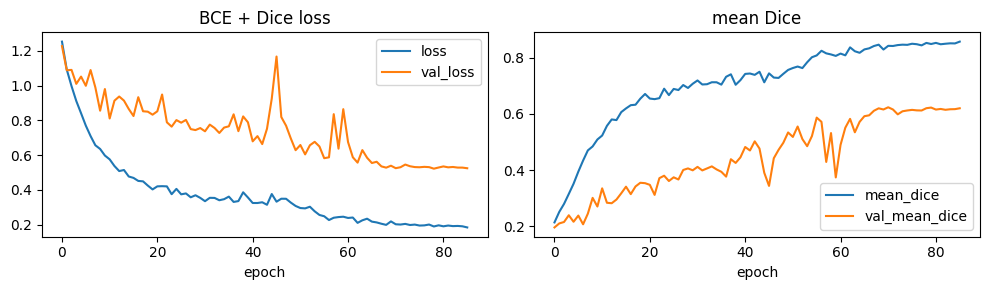

In [ ]:
best_weights = RUN_DIR / 'best.weights.h5'
callbacks = [
    tf.keras.callbacks.ReduceLROnPlateau(monitor='val_mean_dice', mode='max', factor=0.5, patience=5, min_lr=1e-6, verbose=1),
    tf.keras.callbacks.EarlyStopping(monitor='val_mean_dice', mode='max', patience=15, restore_best_weights=True),
    tf.keras.callbacks.ModelCheckpoint(str(best_weights), monitor='val_mean_dice', mode='max',
                                       save_best_only=True, save_weights_only=True),
]

t0 = time.time()
history = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS, callbacks=callbacks)
train_minutes = (time.time() - t0) / 60

hist = pd.DataFrame(history.history)
hist.to_csv(RUN_DIR / 'history.csv', index=False)
print(f'trained {len(hist)} epochs in {train_minutes:.1f} min, best val dice {hist.val_mean_dice.max():.4f}')

fig, ax = plt.subplots(1, 2, figsize=(10, 3))
hist[['loss', 'val_loss']].plot(ax=ax[0], title='BCE + Dice loss', xlabel='epoch')
hist[['mean_dice', 'val_mean_dice']].plot(ax=ax[1], title='mean Dice', xlabel='epoch')
plt.tight_layout()
plt.savefig(RUN_DIR / 'training_curves.png', dpi=120)
plt.show()

**Training:**

- Training stopped after 86 epochs (44 min on the T4). The best validation Dice was **0.6235** at epoch 71.
- The model does seem to overfit, at its best epoch the training Dice was 0.84, while the validation Dice was only 0.62.
- The validation loss is noisy and has a large spike around epoch 45. It settles down later, once the learning rate is lower.

## Predict on the test images

The model predicts 5 masks for each test image and saves them as BMP files, which is the format the evaluation reads. Predictions above 0.5 count as foreground.

The cell also prints an FPS number, but it is not a fair speed measurement (the Keras model is called directly on one image at a time, which is slow), so we do not use it in the comparison.

In [ ]:
PRED_DIR = RUN_DIR / 'predictions'
for c in CLASSES:
    (PRED_DIR / c).mkdir(parents=True, exist_ok=True)

times = []
for i, stem in enumerate(test_stems):
    img = Image.open(test_images[stem]).convert('RGB').resize((IMG_W, IMG_H), Image.BILINEAR)
    x = np.asarray(img, np.float32)[None] / 255.0
    t0 = time.perf_counter()
    prob = model(x, training=False).numpy()[0]
    if i > 0:  # skip the first image (warm-up)
        times.append(time.perf_counter() - t0)
    for k, c in enumerate(CLASSES):
        Image.fromarray(((prob[..., k] > 0.5) * 255).astype(np.uint8)).save(PRED_DIR / c / f'{stem}.bmp')

fps = 1 / np.mean(times) if times else float('nan')
n_params = model.count_params()
print(f'saved predictions for {len(test_stems)} test images')
print(f'params: {n_params:,} | inference: {fps:.1f} FPS (batch 1, {IMG_W}x{IMG_H})')

saved predictions for 110 test images
params: 5,419,541 | inference: 4.6 FPS (batch 1, 320x256)


## Evaluate on the test images

This is the same evaluation as in the SUIM paper: boundary F-score and IoU at 320x240. A class is only scored on the images where it appears in the ground truth and the final score is the average of the 5 class scores. The pixel Dice and the boundary precision/recall are saved as well.

Four of the TEST images are exact copies of training images, so the scores are also shown without them (106 images).

In [ ]:
# evaluation functions from the original SUIM code
def disk(radius):
    y, x = np.ogrid[-radius:radius + 1, -radius:radius + 1]
    return x * x + y * y <= radius * radius

def seg2bmap(seg):
    seg = np.asarray(seg, dtype=bool)
    e, s, se = np.zeros_like(seg), np.zeros_like(seg), np.zeros_like(seg)
    e[:, :-1] = seg[:, 1:]
    s[:-1, :] = seg[1:, :]
    se[:-1, :-1] = seg[1:, 1:]
    boundary = seg ^ e | seg ^ s | seg ^ se
    boundary[-1, :] = seg[-1, :] ^ e[-1, :]
    boundary[:, -1] = seg[:, -1] ^ s[:, -1]
    boundary[-1, -1] = False
    return boundary

def db_eval_boundary(foreground_mask, gt_mask, bound_th=0.008):
    bound_pix = bound_th if bound_th >= 1 else np.ceil(bound_th * np.linalg.norm(foreground_mask.shape))
    fg_boundary = seg2bmap(foreground_mask)
    gt_boundary = seg2bmap(gt_mask)
    fg_dil = binary_dilation(fg_boundary, disk(int(bound_pix)))
    gt_dil = binary_dilation(gt_boundary, disk(int(bound_pix)))
    gt_match = gt_boundary * fg_dil
    fg_match = fg_boundary * gt_dil
    n_fg, n_gt = np.sum(fg_boundary), np.sum(gt_boundary)
    if n_fg == 0 and n_gt > 0:
        precision, recall = 1, 0
    elif n_fg > 0 and n_gt == 0:
        precision, recall = 0, 1
    elif n_fg == 0 and n_gt == 0:
        precision, recall = 1, 1
    else:
        precision = np.sum(fg_match) / float(n_fg)
        recall = np.sum(gt_match) / float(n_gt)
    F = 0 if precision + recall == 0 else 2 * precision * recall / (precision + recall)
    return precision, recall, F

def IoU_bin(target, prediction):
    union = np.logical_or(target, prediction).sum()
    return float(np.logical_and(target, prediction).sum() / union) if union else 1.0

def read_and_bin(path, size):
    with Image.open(path) as source:
        image = source.convert('L').resize(size, Image.BICUBIC)
    return np.asarray(image, dtype=np.float32) / 255.0 >= 0.5

def evaluate(pred_dir, stems):
    rows = []
    for c in CLASSES:
        for stem in stems:
            gt = read_and_bin(gt_masks[c][stem], (EVAL_W, EVAL_H))
            pred = read_and_bin(pred_dir / c / f'{stem}.bmp', (EVAL_W, EVAL_H))
            # only score a class on images where it's in the ground truth
            if not gt.any():
                continue
            p, r, f = db_eval_boundary(pred, gt)
            dice = 2 * (gt & pred).sum() / (gt.sum() + pred.sum())
            rows.append({'stem': stem, 'class': c, 'boundary_f': f, 'iou': IoU_bin(gt, pred),
                         'pixel_dice': dice, 'boundary_precision': p, 'boundary_recall': r})
    per_image = pd.DataFrame(rows)
    return per_image, summarize(per_image)

def summarize(per_image):
    metrics = ['boundary_f', 'iou', 'pixel_dice', 'boundary_precision', 'boundary_recall']
    per_class = per_image.groupby('class', sort=False)[metrics].mean().mul(100).round(2)
    per_class.insert(0, 'images', per_image.groupby('class', sort=False).size())
    return per_class

In [ ]:
per_image, per_class = evaluate(PRED_DIR, test_stems)
per_class_no_overlap = summarize(per_image[~per_image.stem.isin(overlap_stems)])
per_image.to_csv(RUN_DIR / 'per_image_metrics.csv', index=False)
per_class.to_csv(RUN_DIR / 'class_metrics.csv')
per_class_no_overlap.to_csv(RUN_DIR / 'class_metrics_no_overlap.csv')
n_no_overlap = len(set(test_stems) - set(overlap_stems))

print(f'All {len(test_stems)} test images')
display(per_class)
print(f'Without the overlapping images ({n_no_overlap} test images)')
display(per_class_no_overlap)

summary = {
    'model': MODEL_LABEL, 'notebook': '09_mobilenetv2_unet', 'quick_test': QUICK_TEST,
    'input_size_wh': [IMG_W, IMG_H], 'eval_size_wh': [EVAL_W, EVAL_H],
    'train_images': len(train_stems), 'val_images': len(val_stems), 'test_images': len(test_stems),
    'epochs_trained': len(hist), 'train_minutes': round(train_minutes, 1),
    'params': int(n_params), 'fps': round(float(fps), 1),
    'macro_boundary_f': round(float(per_class.boundary_f.mean()), 2),
    'macro_iou': round(float(per_class.iou.mean()), 2),
    'macro_pixel_dice': round(float(per_class.pixel_dice.mean()), 2),
    'test_images_no_overlap': n_no_overlap, 'overlap_stems': overlap_stems,
    'macro_boundary_f_no_overlap': round(float(per_class_no_overlap.boundary_f.mean()), 2),
    'macro_iou_no_overlap': round(float(per_class_no_overlap.iou.mean()), 2),
}
(RUN_DIR / 'summary.json').write_text(json.dumps(summary, indent=2))
print(json.dumps(summary, indent=2))

All 110 test images


,images,boundary_f,iou,pixel_dice,boundary_precision,boundary_recall
class,,,,,,
RO,12,58.66,57.09,65.74,84.16,54.98
FV,66,66.80,61.44,69.37,79.98,64.65
HD,42,73.91,70.65,76.78,92.15,72.44
RI,58,46.72,64.71,73.19,54.66,46.93
WR,27,49.26,58.82,65.56,71.58,49.20


Without the overlapping images (106 test images)


,images,boundary_f,iou,pixel_dice,boundary_precision,boundary_recall
class,,,,,,
RO,10,63.64,62.91,71.71,84.60,58.81
FV,65,66.43,61.27,69.15,79.74,64.32
HD,39,72.80,69.68,75.70,91.89,71.68
RI,56,46.19,64.70,73.14,54.41,46.42
WR,26,48.29,57.63,64.45,70.75,48.71


{
  "model": "MobileNetV2 U-Net",
  "notebook": "09_mobilenetv2_unet",
  "quick_test": false,
  "input_size_wh": [
    320,
    256
  ],
  "eval_size_wh": [
    320,
    240
  ],
  "train_images": 1220,
  "val_images": 305,
  "test_images": 110,
  "epochs_trained": 86,
  "train_minutes": 44.0,
  "params": 5419541,
  "fps": 4.6,
  "macro_boundary_f": 59.07,
  "macro_iou": 62.54,
  "macro_pixel_dice": 70.13,
  "test_images_no_overlap": 106,
  "overlap_stems": [
    "d_r_386_",
    "n_l_0_",
    "n_l_29_",
    "n_l_87_"
  ],
  "macro_boundary_f_no_overlap": 59.47,
  "macro_iou_no_overlap": 63.24
}


**Results:**

| Test images | Boundary F | IoU | Pixel Dice |
|---|---|---|---|
| All 110 | **59.07** | **62.54** | 70.13 |
| Without the 4 copies (106) | 59.47 | 63.24 | 70.83 |

- The model reaches **59.07** boundary F and **62.54** IoU. This is still well below the pretrained SUIM-Net RSB from the paper (74.80 / 76.67 in our SUIM-Net notebook).
- These scores cannot be compared directly with the 58.5% F1 / 52.1% IoU from our earlier version, since that one used pixel F1 and also counted images where the class is not in the ground truth.
- Divers are the best class (73.91 F). Reefs have the lowest boundary F (46.72) even though their IoU comes out fine (64.71), so the model finds roughly the right area but the edges are off. This can be expected, since reefs do not really have a clear outline.
- The boundary precision is higher than the recall for every class (92.15 vs 72.44 for divers). The edges that the model predicts are mostly correct, but it misses many of the real ones.
- Without the four copied images the scores are slightly higher, so the copies did not inflate the results. However the robots only have 12 test images, so this class changes a lot since 2 of them are removed (58.66 to 63.64 F).

The full comparison with our other models is at the end of the SegFormer notebook (10).

## Show example predictions

The first 4 test images with their ground truth and the prediction. The colors follow the SUIM labels: red = robots, yellow = fish, blue = divers, magenta = reefs, cyan = wrecks and black = background.

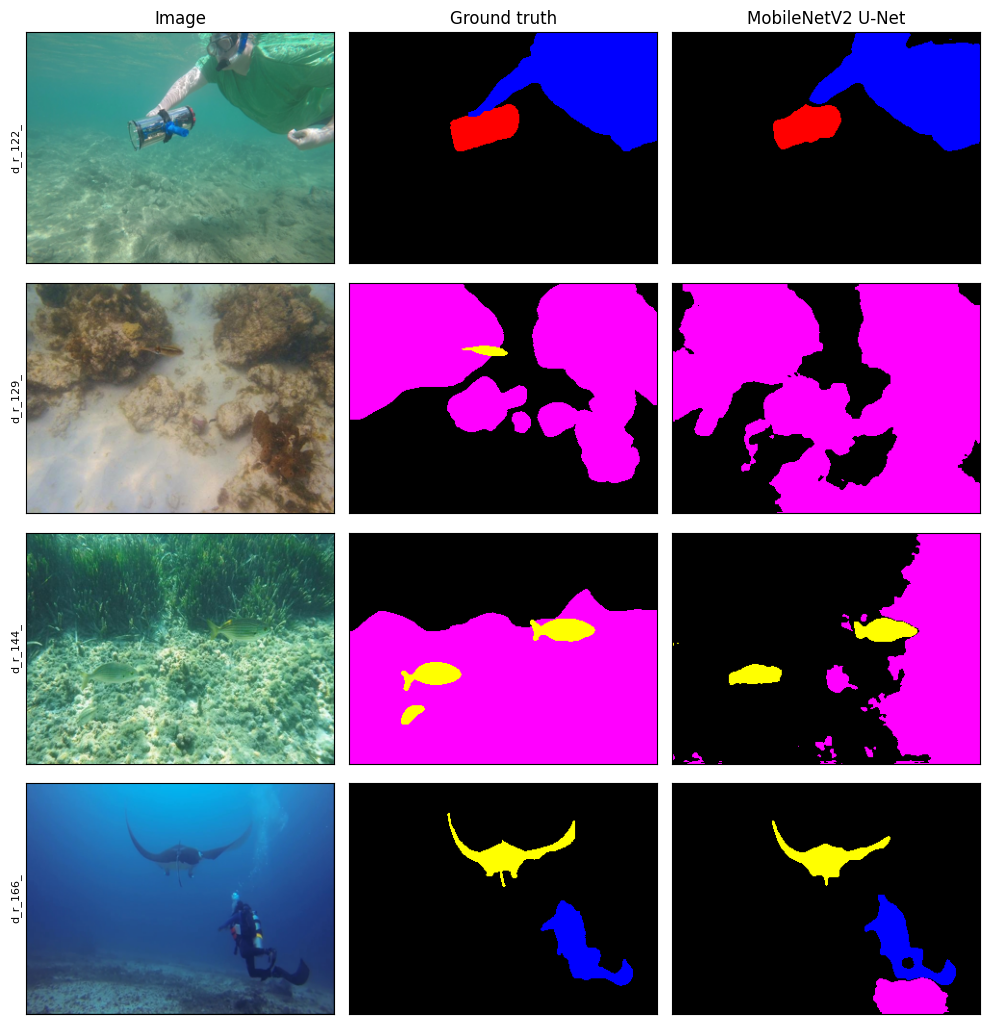

In [ ]:
COLORS = {'RO': (255, 0, 0), 'FV': (255, 255, 0), 'HD': (0, 0, 255), 'RI': (255, 0, 255), 'WR': (0, 255, 255)}

def color_mask(paths):
    out = np.zeros((EVAL_H, EVAL_W, 3), np.uint8)
    for c, path in paths.items():
        out[read_and_bin(path, (EVAL_W, EVAL_H))] = COLORS[c]
    return out

examples = test_stems[:4]  # same images for every model so the figures can be compared
fig, axes = plt.subplots(len(examples), 3, figsize=(10, 2.6 * len(examples)), squeeze=False)
for row, stem in enumerate(examples):
    axes[row, 0].imshow(Image.open(test_images[stem]).convert('RGB').resize((EVAL_W, EVAL_H)))
    axes[row, 1].imshow(color_mask({c: gt_masks[c][stem] for c in CLASSES}))
    axes[row, 2].imshow(color_mask({c: PRED_DIR / c / f'{stem}.bmp' for c in CLASSES}))
    axes[row, 0].set_ylabel(stem, fontsize=8)
for ax, title in zip(axes[0], ['Image', 'Ground truth', MODEL_LABEL]):
    ax.set_title(title)
for ax in axes.flat:
    ax.set_xticks([])
    ax.set_yticks([])
plt.tight_layout()
plt.savefig(RUN_DIR / 'examples.png', dpi=120)
plt.show()

**What do the predictions look like?**

- The diver and the robot in the first image, and the ray and the diver in the last one, are close to the ground truth.
- The reef images are the difficult ones. In the second image the reef covers roughly the right area, but the shape is off and the small fish was completely missed.
- In the third image the ground truth labels most of the bottom as reef, but the model mostly predicts reef on the right side.
- In the last image the model predicts a reef patch at the bottom that is not in the ground truth.